# Chapitre 11 - Cours 1 : projection pursuit regression et passage aux réseaux de neurones

Ce premier notebook couvre les sections 11.1 à 11.3 du livre :

1. l'idée commune aux méthodes du chapitre : construire des **variables dérivées**, combinaisons
   linéaires des entrées, puis modéliser la réponse comme une fonction **non linéaire** de
   ces variables ;
2. le modèle de **projection pursuit regression** (PPR, éq. (11.1)) et les **fonctions ridge**
   (figure 11.1) ;
3. l'ajustement de la PPR : lissage par spline et étape de **Gauss–Newton** (éq. (11.2)–(11.4)) ;
4. le **réseau de neurones à une couche cachée** (éq. (11.5)–(11.7), figures 11.2 et 11.3), vu
   comme une PPR dont les fonctions ridge sont des sigmoïdes paramétrées.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl.ch11_reseaux import PPR, SmoothingSpline, sigmoid

## 1. Le modèle de projection pursuit regression

On dispose d'un vecteur d'entrées $X \in \mathbb{R}^p$ et d'une réponse quantitative $Y$.
Soient $\omega_1, \dots, \omega_M$ des vecteurs **unitaires** de $\mathbb{R}^p$ (inconnus,
$\|\omega_m\| = 1$). Le modèle PPR s'écrit

$$f(X) = \sum_{m=1}^{M} g_m(\omega_m^T X) \qquad \text{(éq. (11.1) du livre).}$$

C'est un **modèle additif** (chapitre 9), mais additif en les **variables dérivées**
$V_m = \omega_m^T X$ et non en les entrées $X_j$ elles-mêmes. Les fonctions
$g_m : \mathbb{R} \to \mathbb{R}$ ne sont pas spécifiées à l'avance : elles sont estimées
en même temps que les directions $\omega_m$.

### Fonctions ridge

Une fonction de la forme $x \mapsto g(\omega^T x)$ s'appelle une **fonction ridge** (« fonction
crête »). Le nombre $V = \omega^T x$ est la **projection** de $x$ sur la droite dirigée par le
vecteur unitaire $\omega$.

> **Intuition.** Une fonction ridge ne varie que dans **une seule direction**, celle de $\omega$.
> Si l'on se déplace orthogonalement à $\omega$, c'est-à-dire de $x$ à $x + u$ avec
> $\omega^T u = 0$, la projection ne change pas : $\omega^T(x+u) = \omega^T x$, donc
> $g(\omega^T(x+u)) = g(\omega^T x)$. Le graphe ressemble à une « tôle ondulée » dont les plis
> sont orthogonaux à $\omega$.

La figure 11.1 du livre montre deux fonctions ridge sur $\mathbb{R}^2$ :

* à gauche, $g(V) = 1/[1 + \exp(-5(V - 0{,}5))]$ avec $V = (X_1 + X_2)/\sqrt{2}$, soit
  $\omega = (1, 1)^T/\sqrt 2$ ;
* à droite, $g(V) = (V + 0{,}1)\sin\big(1/(V/3 + 0{,}1)\big)$ avec $V = X_1$, soit $\omega = (1, 0)^T$.

Les entrées sont prises dans le carré $[0,1]^2$.

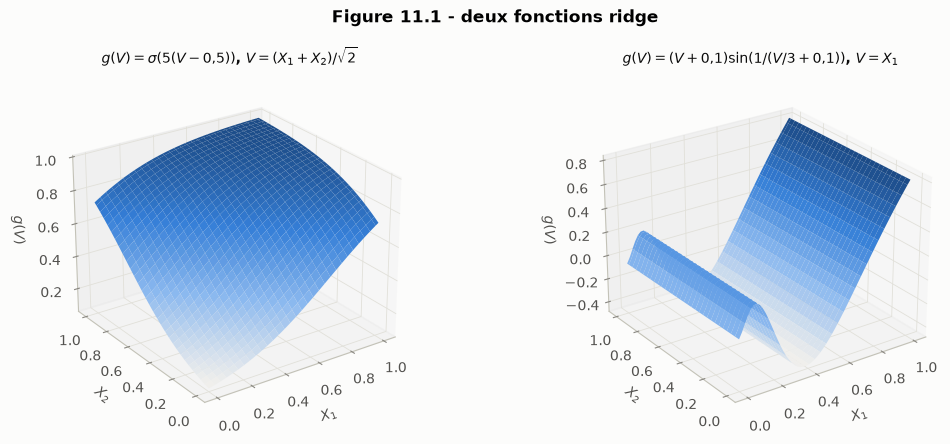

In [2]:
grid = np.linspace(0, 1, 60)
X1, X2 = np.meshgrid(grid, grid)
G_left = 1 / (1 + np.exp(-5 * ((X1 + X2) / np.sqrt(2) - 0.5)))
G_right = (X1 + 0.1) * np.sin(1 / (X1 / 3 + 0.1))

fig = plt.figure(figsize=(11, 4.5))
for j, (G, titre) in enumerate([(G_left, r"$g(V)=\sigma(5(V-0{,}5))$, $V=(X_1+X_2)/\sqrt{2}$"),
                                (G_right, r"$g(V)=(V+0{,}1)\sin(1/(V/3+0{,}1))$, $V=X_1$")]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    ax.plot_surface(X1, X2, G, cmap=SEQ, linewidth=0, antialiased=True, alpha=0.95)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_zlabel("$g(V)$")
    ax.set_title(titre, fontsize=10)
    ax.view_init(elev=25, azim=-125)
fig.suptitle("Figure 11.1 - deux fonctions ridge", fontweight="bold")
plt.tight_layout()
plt.show()

Vérifions numériquement l'invariance : pour la fonction de gauche, un déplacement le long de
$u = (1, -1)^T$ (orthogonal à $\omega$) ne change pas la valeur.

In [3]:
def g_left(x1, x2):
    return 1 / (1 + np.exp(-5 * ((x1 + x2) / np.sqrt(2) - 0.5)))

rng = np.random.RandomState(0)
pts = rng.uniform(0, 1, (5, 2))
t = rng.uniform(-0.3, 0.3, 5)
print("g(x)         :", np.round(g_left(pts[:, 0], pts[:, 1]), 6))
print("g(x + t*u)   :", np.round(g_left(pts[:, 0] + t, pts[:, 1] - t), 6))

g(x)         : [0.877496 0.826001 0.782692 0.900249 0.905743]
g(x + t*u)   : [0.877496 0.826001 0.782692 0.900249 0.905743]
